# 01. 문제 정의와 이미지 EDA

피트니스 운동 장면 이미지 한 장으로 **운동 종류 12개**를 분류하는 문제를 정의하고, Train 데이터의 구조와 시각적 특성을 살펴봅니다.

**이 노트북의 규칙**
- 분포·이미지 분석은 **Train만** 합니다. Validation은 분할 크기만 확인하고, Test는 열지 않습니다(무결성 검사는 별도로 마쳤음).
- 공식 분할(사람 코드 기준 Train 16명 / Val 3명 / Test 3명)을 그대로 씁니다.
- 원본 이미지가 들어간 그림은 `figures/samples/`에 저장하고 Git에서 제외합니다(AI Hub 이용 조건 확인 전).

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
sys.path.insert(0, str(ROOT / "src"))
from common import DATA_RAW, FIGURES, FIGURES_SAMPLES, GROUPS, CLASS_TO_GROUP, load_metadata, class_names, set_korean_font

FIGURES.mkdir(exist_ok=True); FIGURES_SAMPLES.mkdir(parents=True, exist_ok=True)
print("font:", set_korean_font())
pd.set_option("display.width", 160)
RNG = np.random.default_rng(42)

NAMES = class_names()
tr = load_metadata("train")
va = load_metadata("val")          # 분할 크기 확인용으로만 사용
print("train", tr.shape, "| val", va.shape)

font: Malgun Gothic
train (8144, 16) | val (1440, 16)


## 1. 문제 정의

### 1.1 분류 대상과 Target
- **입력**: 운동 장면 RGB 이미지 1장(384×216). 메타데이터의 `equipment`, `pose`, `camera`, `state_code` 등은 **입력으로 쓰지 않습니다**(데이터 README 규칙). 이미지에서만 판단해야 합니다.
- **Target**: `target_id`(0~11). 한 이미지에 정답 하나인 다중 클래스 분류입니다.
- **목표 범위**: 운동 *종류* 식별입니다. 자세가 올바른지, 몇 회 했는지, 부상 위험은 판단하지 않습니다.
- **활용 장면**: 운동 콘텐츠 자동 태깅, 운동 장면 검색, 운동 기록 앱에서 종목 자동 입력.

### 1.2 클래스의 의미(도메인 설명)

| id | 운동 | 동작 요약 | 구분 단서 |
|---|---|---|---|
| 0 | Y - Exercise | 엎드려 팔을 머리 위 Y자로 들어 올리는 등·어깨 후면 운동 | 엎드린 자세 + 팔이 머리 위로 뻗음 |
| 1 | 니푸쉬업 | 무릎을 바닥에 대고 하는 팔굽혀펴기 | 엎드린 자세 + 손바닥 지지, 상체가 들림 |
| 2 | 덤벨 벤트오버 로우 | 상체를 숙이고 덤벨을 몸 쪽으로 당김 | 숙인 자세 + **덤벨 두 개** |
| 3 | 딥스 | 평행 바를 잡고 팔로 몸을 내렸다 밀어 올림 | 낮은 평행 바(노란색) 사이의 사람 |
| 4 | 라잉 레그 레이즈 | 누워서 다리를 곧게 들어 올림 | 누운 자세 + 두 다리가 함께 위로 |
| 5 | 랫풀 다운 | 앉아서 머리 위 바를 가슴 쪽으로 당김 | 케이블 머신에 **앉은** 자세, 팔이 위 |
| 6 | 로잉머신 | 로잉 에르고미터에서 손잡이를 당기며 다리로 밂 | 바닥 가까이 앉은 자세 + 긴 레일 기구 |
| 7 | 바벨 데드리프트 | 엉덩이를 접었다 펴며 바닥의 바벨을 들어 올림 | 바벨 + 숙인 자세 ↔ 선 자세를 오감 |
| 8 | 바벨 런지 | 바벨을 어깨에 메고 한 발 앞으로 내딛어 앉음 | 바벨이 **어깨 위** + 다리 앞뒤 벌림 |
| 9 | 바벨 로우 | 상체를 숙인 채 바벨을 배 쪽으로 당김 | 바벨 + 숙인 자세가 **유지됨** |
| 10 | 바이시클 크런치 | 누워서 팔꿈치와 반대쪽 무릎을 번갈아 맞댐 | 누운 자세 + 다리가 교차 |
| 11 | 케이블 크런치 | 케이블 머신 앞에서 로프를 잡고 몸통을 말아 숙임 | 케이블 머신 + 몸통 굽힘 |

### 1.3 어떤 오류가 중요한가
- 아래 3절과 7절에서 보이듯, 이 데이터는 **운동 묶음(맨몸 / 바벨·덤벨 / 기구)마다 촬영 공간이 다릅니다.** 그래서 묶음이 다른 운동끼리는 배경만으로도 구분되고, 그 사이의 오류는 드물 것으로 예상합니다.
- 진짜 어려운 것은 **같은 묶음 안의 구분**입니다. 특히
  - **2 덤벨 벤트오버 로우 ↔ 9 바벨 로우 ↔ 7 바벨 데드리프트**: 모두 상체를 숙인 자세입니다. 데드리프트의 내려간 순간은 바벨 로우와 거의 같아 보이고, 덤벨과 바벨의 차이는 작은 물체 하나입니다.
  - **5 랫풀 다운 ↔ 11 케이블 크런치**: 둘 다 케이블 머신을 씁니다.
  - **0 Y-Exercise ↔ 1 니푸쉬업**, **4 라잉 레그 레이즈 ↔ 10 바이시클 크런치**: 같은 바닥 자세 계열입니다.
- 콘텐츠 태깅에서는 12종이 모두 똑같이 중요하고, 특정 종목을 놓치는 비용이 다른 종목보다 크다는 근거는 없습니다.

### 1.4 평가 지표(학습 전에 확정)
- **핵심 지표: Validation Macro F1.** 클래스마다 F1을 구해 단순 평균합니다. 클래스 크기와 상관없이 12종을 똑같이 반영합니다. Train 클래스 크기가 최대 3.6배 차이 나서(3절), Accuracy는 큰 클래스에 끌려갈 수 있습니다.
- **보조 지표**: Accuracy, 클래스별 Precision·Recall·F1, Confusion Matrix(묶음 단위로 읽기).
- **해석 주의**: Validation은 운동마다 **사람 1명**입니다. 작은 점수 차이(예: 0.01)는 그 한 사람의 습관 때문일 수 있습니다.

## 2. 데이터 구조

In [2]:
print("columns:", list(tr.columns))
summary = pd.DataFrame({
    "images": [len(tr), len(va)],
    "persons": [tr.person_id.nunique(), va.person_id.nunique()],
    "clips": [tr.clip_id.nunique(), va.clip_id.nunique()],
    "classes": [tr.target_id.nunique(), va.target_id.nunique()],
}, index=["train", "val"])
summary.loc["test(공식 표)"] = [1432, 3, 179, 12]
summary

columns: ['image_id', 'image_path', 'split', 'target_id', 'exercise', 'equipment', 'pose', 'person_id', 'source_subject_id', 'clip_id', 'state_code', 'camera', 'frame_no', 'width', 'height', 'file_size_bytes']


,images,persons,clips,classes
train,8144,16,1018,12
val,1440,3,180,12
test(공식 표),1432,3,179,12


In [3]:
# 클립 하나의 구성: 카메라 5대(A~E) × frame_no 4개 중 8장
g = tr.groupby("clip_id").agg(n=("image_id", "size"), cams=("camera", "nunique"), frames=("frame_no", "nunique"))
print("클립당 (이미지, 카메라 수, 프레임 수):", g.value_counts().to_dict())
ex = tr[tr.clip_id == tr.clip_id.iloc[0]].sort_values(["frame_no", "camera"])
pd.crosstab(ex.frame_no, ex.camera)

클립당 (이미지, 카메라 수, 프레임 수): {(8, 5, 4): 1018}


camera,A,B,C,D,E
frame_no,,,,,
1,0,0,0,1,1
9,1,1,0,0,0
19,0,0,1,1,0
27,1,0,0,0,1


**읽는 법**: 클립 하나는 *한 사람이 한 운동을 한 번 수행한 장면*을 카메라 5대로 동시에 찍은 것입니다. 그중 4개 시점(frame_no)에서 8장을 뽑았습니다. 같은 순간을 다른 각도에서 찍은 사진이 한 클립 안에 들어 있으므로, 8장은 서로 독립된 표본이 아닙니다. 실질 표본 수는 클립 수(Train 1,018)에 가깝습니다.

## 3. Train 클래스 분포와 불균형

In [4]:
per_cls = tr.groupby("target_id").agg(images=("image_id", "size"), clips=("clip_id", "nunique"), persons=("person_id", "nunique"))
per_cls.insert(0, "exercise", per_cls.index.map(NAMES))
per_cls["group"] = per_cls.index.map(CLASS_TO_GROUP)
per_cls["val_images"] = va.groupby("target_id").size()
print(f"불균형(최대/최소 이미지 수): {per_cls.images.max()} / {per_cls.images.min()} = {per_cls.images.max() / per_cls.images.min():.2f}")
per_cls

불균형(최대/최소 이미지 수): 1120 / 312 = 3.59


,exercise,images,clips,persons,group,val_images
target_id,,,,,,
0,Y - Exercise,320,40,5,맨몸(바닥),64
1,니푸쉬업,800,100,5,맨몸(바닥),160
2,덤벨 벤트오버 로우,800,100,5,바벨·덤벨(선 자세),160
3,딥스,896,112,7,기구,128
4,라잉 레그 레이즈,640,80,5,맨몸(바닥),128
5,랫풀 다운,888,111,7,기구,128
6,로잉머신,1120,140,7,기구,160
7,바벨 데드리프트,800,100,5,바벨·덤벨(선 자세),160
8,바벨 런지,800,100,5,바벨·덤벨(선 자세),160


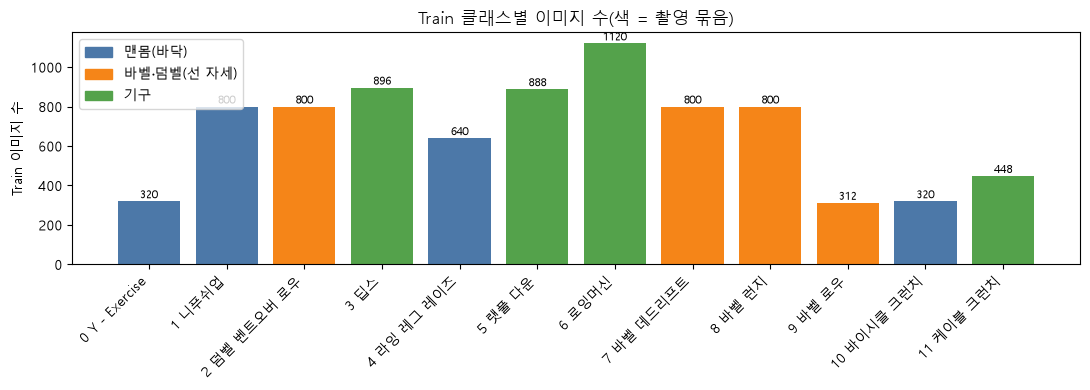

In [5]:
colors = {"맨몸(바닥)": "#4C78A8", "바벨·덤벨(선 자세)": "#F58518", "기구": "#54A24B"}
fig, ax = plt.subplots(figsize=(11, 4))
ax.bar([f"{i} {NAMES[i]}" for i in per_cls.index], per_cls.images, color=[colors[g] for g in per_cls.group])
for i, v in enumerate(per_cls.images):
    ax.text(i, v + 15, str(v), ha="center", fontsize=8)
ax.set_ylabel("Train 이미지 수"); ax.set_title("Train 클래스별 이미지 수(색 = 촬영 묶음)")
ax.tick_params(axis="x", rotation=45)
for lab in ax.get_xticklabels(): lab.set_ha("right")
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in colors.values()]
ax.legend(handles, colors.keys(), loc="upper left")
fig.tight_layout(); fig.savefig(FIGURES / "eda_class_distribution.png", dpi=150); plt.show()

## 4. 사람 코드와 운동의 관계

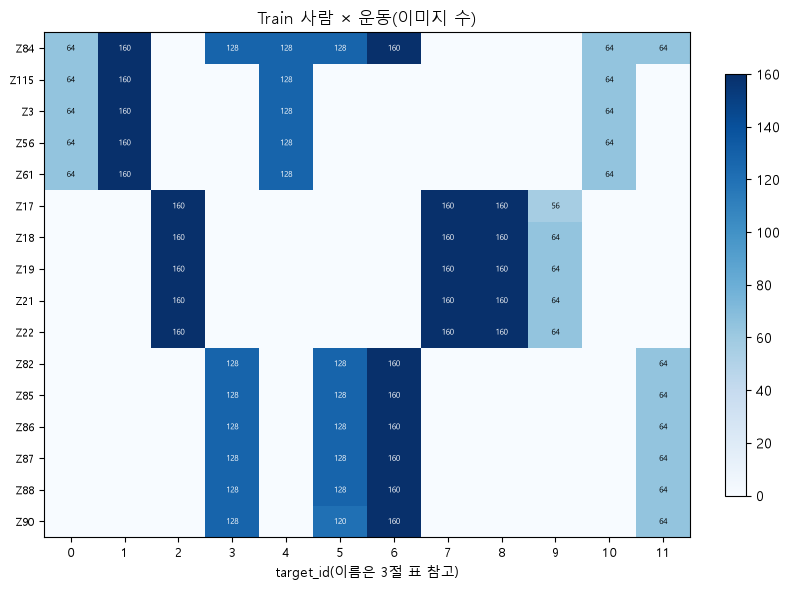

두 묶음 이상을 수행한 사람: {'Z84': ['기구', '맨몸(바닥)']}


In [6]:
pc = pd.crosstab(tr.person_id, tr.target_id)
order = sorted(pc.index, key=lambda p: (tuple(pc.loc[p] == 0), p))
pc = pc.loc[order]
fig, ax = plt.subplots(figsize=(8, 6))
im = ax.imshow(pc.values, cmap="Blues", aspect="auto")
ax.set_xticks(range(12)); ax.set_xticklabels(pc.columns, fontsize=9); ax.set_xlabel("target_id(이름은 3절 표 참고)")
ax.set_yticks(range(len(pc))); ax.set_yticklabels(pc.index, fontsize=8)
for (r, c), v in np.ndenumerate(pc.values):
    if v: ax.text(c, r, v, ha="center", va="center", fontsize=6, color="white" if v > 100 else "black")
ax.set_title("Train 사람 × 운동(이미지 수)")
fig.colorbar(im, ax=ax, fraction=0.03); fig.tight_layout(); fig.savefig(FIGURES / "eda_person_class.png", dpi=150); plt.show()

grp_per_person = tr.assign(group=tr.target_id.map(CLASS_TO_GROUP)).groupby("person_id").group.unique()
print("두 묶음 이상을 수행한 사람:", {p: list(g) for p, g in grp_per_person.items() if len(g) > 1})

**읽는 법**: 사람마다 한 묶음(맨몸 4종, 바벨·덤벨 4종, 기구 4종)을 통째로 수행했습니다(Z84만 두 묶음). 그래서 "이 사람이면 이 묶음"이라는 관계가 강합니다. Val/Test에는 새로운 사람이 나오므로, 모델이 사람(옷, 체형)을 외우면 일반화되지 않습니다. 반대로 묶음 *안*에서는 같은 사람이 4종을 모두 했으므로, 사람 특징으로는 운동을 구분할 수 없고 동작을 봐야 합니다. 이 점은 학습에 유리합니다.

## 5. 카메라 시점

In [7]:
cam = pd.crosstab(tr.target_id.map(lambda i: f"{i} {NAMES[i]}"), tr.camera)
print("카메라별 Train 이미지:", tr.camera.value_counts().sort_index().to_dict())
cam

카메라별 Train 이미지: {'A': 1652, 'B': 1645, 'C': 1609, 'D': 1599, 'E': 1639}


camera,A,B,C,D,E
target_id,,,,,
0 Y - Exercise,65,63,63,65,64
1 니푸쉬업,172,167,153,147,161
10 바이시클 크런치,67,70,63,59,61
11 케이블 크런치,89,93,90,90,86
2 덤벨 벤트오버 로우,159,158,161,162,160
3 딥스,186,182,174,168,186
4 라잉 레그 레이즈,120,122,128,137,133
5 랫풀 다운,180,181,177,173,177
6 로잉머신,225,224,215,223,233


In [8]:
# 같은 클립을 카메라 5대로 본 모습(클래스마다 클립 1개)
W, H = 192, 108
fig, axes = plt.subplots(12, 5, figsize=(12, 15))
for r, c in enumerate(sorted(tr.target_id.unique())):
    clips = tr[tr.target_id == c].clip_id.unique()
    clip = clips[RNG.integers(len(clips))]
    rows = tr[tr.clip_id == clip].drop_duplicates("camera").set_index("camera")
    for k, cam_id in enumerate("ABCDE"):
        ax = axes[r, k]; ax.axis("off")
        if cam_id in rows.index:
            ax.imshow(Image.open(DATA_RAW / rows.loc[cam_id, "image_path"]).resize((W, H)))
        if r == 0: ax.set_title(f"camera {cam_id}")
    axes[r, 0].text(-10, H / 2, f"{c} {NAMES[c]}", ha="right", va="center", fontsize=9)
fig.tight_layout(); fig.savefig(FIGURES_SAMPLES / "eda_clip_by_camera.jpg", dpi=110); plt.show()

[원본 사진 그림 출력은 지웠습니다. 로컬 파일 figures/samples/에 저장되어 있고, 공개 저장소에는 넣지 않습니다(AI Hub 이용 조건).]


**읽는 법**: 카메라 5대는 운동과 상관없이 고르게 쓰였습니다(위 표). 같은 동작도 정면·측면·대각선에 따라 모습이 크게 다릅니다. 측면에서는 상체 각도와 바벨 경로가 잘 보이지만, 정면에서는 숙인 정도를 판단하기 어렵습니다. 2·7·9 혼동은 정면 카메라에서 더 심할 것이라는 가설을 세울 수 있습니다(오류 분석 때 확인).

## 6. 클래스별 대표 이미지

In [9]:
fig, axes = plt.subplots(12, 4, figsize=(10, 15))
for r, c in enumerate(sorted(tr.target_id.unique())):
    pick = tr[tr.target_id == c].sample(4, random_state=int(c))
    for k, row in enumerate(pick.itertuples()):
        ax = axes[r, k]; ax.axis("off")
        ax.imshow(Image.open(DATA_RAW / row.image_path))
        ax.set_title(f"{row.person_id} cam{row.camera} f{row.frame_no}", fontsize=7)
    axes[r, 0].text(-20, 108, f"{c} {NAMES[c]}", ha="right", va="center", fontsize=9)
fig.tight_layout(); fig.savefig(FIGURES_SAMPLES / "eda_class_examples.jpg", dpi=110); plt.show()

[원본 사진 그림 출력은 지웠습니다. 로컬 파일 figures/samples/에 저장되어 있고, 공개 저장소에는 넣지 않습니다(AI Hub 이용 조건).]


## 7. 배경과 촬영 공간: 클래스별 평균 이미지

In [10]:
# 이미지를 96×54로 줄여 클래스별 평균을 낸다. 평균 이미지에는 움직이지 않는 배경이 또렷하게 남는다.
SMALL = (96, 54)
arr = {}
for row in tr.itertuples():
    arr.setdefault(row.target_id, []).append(np.asarray(Image.open(DATA_RAW / row.image_path).resize(SMALL), dtype=np.float32) / 255)
small = {c: np.stack(v) for c, v in arr.items()}
means = {c: v.mean(0) for c, v in small.items()}

fig, axes = plt.subplots(3, 4, figsize=(12, 5))
for ax, (g, cs) in zip(axes, GROUPS.items()):
    for a, c in zip(ax, cs):
        a.imshow(means[c]); a.axis("off"); a.set_title(f"{c} {NAMES[c]}", fontsize=8)
fig.suptitle("클래스별 Train 평균 이미지(행 = 촬영 묶음)")
fig.tight_layout(); fig.savefig(FIGURES_SAMPLES / "eda_class_mean_images.jpg", dpi=120); plt.show()

[원본 사진 그림 출력은 지웠습니다. 로컬 파일 figures/samples/에 저장되어 있고, 공개 저장소에는 넣지 않습니다(AI Hub 이용 조건).]


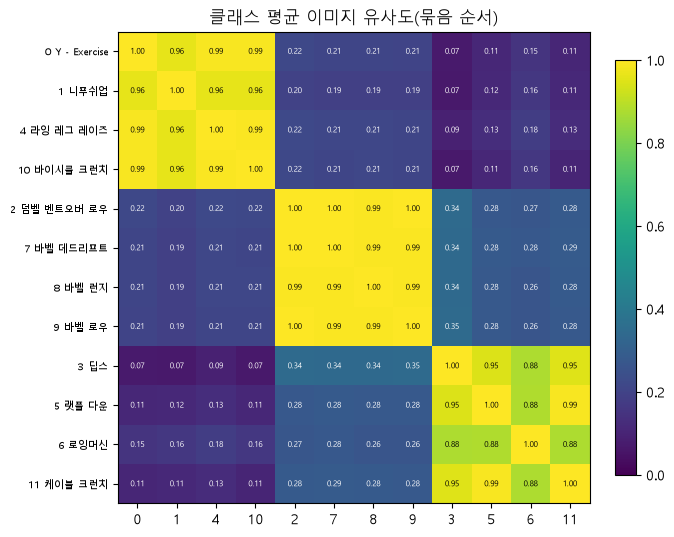

평균 유사도 — 같은 묶음 0.964 / 다른 묶음 0.206


In [11]:
# 평균 이미지끼리의 유사도(코사인). 같은 묶음끼리 높고 다른 묶음끼리 낮다면 배경이 묶음을 알려 준다는 뜻.
ids = [c for cs in GROUPS.values() for c in cs]
V = np.stack([means[c].ravel() - means[c].mean() for c in ids])
V /= np.linalg.norm(V, axis=1, keepdims=True)
S = V @ V.T
fig, ax = plt.subplots(figsize=(6.5, 5.5))
im = ax.imshow(S, vmin=0, vmax=1, cmap="viridis")
ax.set_xticks(range(12)); ax.set_xticklabels(ids); ax.set_yticks(range(12)); ax.set_yticklabels([f"{c} {NAMES[c]}" for c in ids], fontsize=7)
for (r, c), v in np.ndenumerate(S): ax.text(c, r, f"{v:.2f}", ha="center", va="center", fontsize=6, color="white" if v < .6 else "black")
ax.set_title("클래스 평균 이미지 유사도(묶음 순서)"); fig.colorbar(im, fraction=0.04)
fig.tight_layout(); fig.savefig(FIGURES / "eda_mean_image_similarity.png", dpi=150); plt.show()

grp = np.array([CLASS_TO_GROUP[c] for c in ids])
same = S[(grp[:, None] == grp[None, :]) & ~np.eye(12, dtype=bool)].mean()
diff = S[grp[:, None] != grp[None, :]].mean()
print(f"평균 유사도 — 같은 묶음 {same:.3f} / 다른 묶음 {diff:.3f}")

## 8. 이미지 품질: 밝기·대비·근사 중복

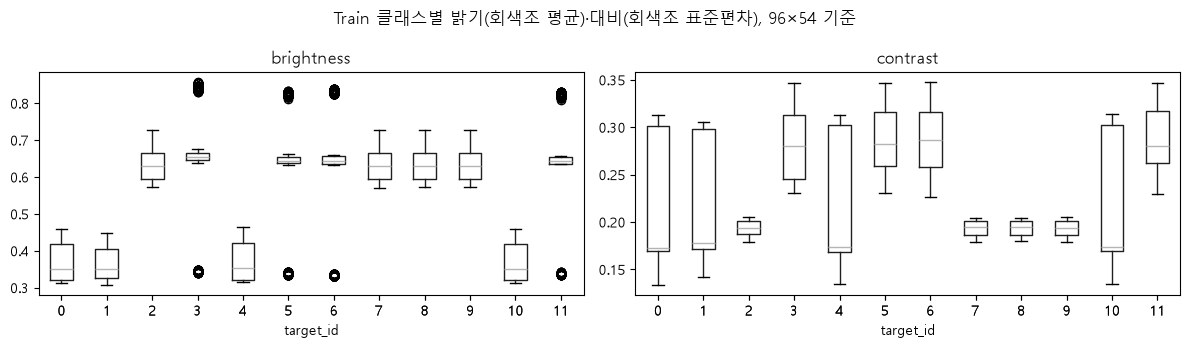

target_id           0      1      2      3      4      5      6      7      8      9      10     11
brightness mean  0.372  0.368  0.639  0.626  0.373  0.618  0.619  0.638  0.639  0.637  0.372  0.619
           std   0.055  0.047  0.049  0.161  0.055  0.157  0.161  0.049  0.048  0.048  0.054  0.157
contrast   mean  0.219  0.221  0.193  0.284  0.218  0.287  0.287  0.193  0.193  0.194  0.219  0.288
           std   0.073  0.067  0.008  0.041  0.072  0.039  0.041  0.008  0.008  0.008  0.072  0.039

In [12]:
stats = []
for c, v in small.items():
    gray = v.mean(-1)                      # (N, H, W)
    for b, s in zip(gray.mean((1, 2)), gray.std((1, 2))):
        stats.append((c, b, s))
st = pd.DataFrame(stats, columns=["target_id", "brightness", "contrast"])
fig, axes = plt.subplots(1, 2, figsize=(12, 3.5), sharex=True)
for ax, col in zip(axes, ["brightness", "contrast"]):
    st.boxplot(column=col, by="target_id", ax=ax, grid=False)
    ax.set_title(col); ax.set_xlabel("target_id")
fig.suptitle("Train 클래스별 밝기(회색조 평균)·대비(회색조 표준편차), 96×54 기준")
fig.tight_layout(); fig.savefig(FIGURES / "eda_brightness_contrast.png", dpi=150); plt.show()
st.groupby("target_id")[["brightness", "contrast"]].agg(["mean", "std"]).round(3).T

In [13]:
# 근사 중복: 32×18 회색조 dHash(64비트에 가깝게 32×17 비교 → 544비트)로 서로 다른 클립 사이에 거의 같은 이미지가 있는지 본다.
def dhash(path, size=(33, 18)):
    g = np.asarray(Image.open(path).convert("L").resize(size), dtype=np.int16)
    return (g[:, 1:] > g[:, :-1]).ravel()

H_ = np.stack([dhash(DATA_RAW / p) for p in tr.image_path])           # (N, 544) bool
Hb = np.packbits(H_, axis=1)
POP = np.array([bin(i).count("1") for i in range(256)], dtype=np.uint8)
clip_arr = tr.clip_id.to_numpy()
near = []
for i in range(len(Hb)):
    d = POP[np.bitwise_xor(Hb[i + 1:], Hb[i])].sum(1)
    for j in np.nonzero(d <= 20)[0] + i + 1:
        near.append((i, j, int(d[j - i - 1]), clip_arr[i] == clip_arr[j]))
near = pd.DataFrame(near, columns=["i", "j", "hamming", "same_clip"])
print(f"해밍 거리 ≤20 / 544비트인 쌍: {len(near)} (같은 클립 {int(near.same_clip.sum())}, 다른 클립 {int((~near.same_clip).sum())})")
if len(near):
    x = near[~near.same_clip].merge(tr[["target_id", "person_id", "camera"]], left_on="i", right_index=True) \
        .merge(tr[["target_id", "person_id", "camera"]], left_on="j", right_index=True, suffixes=("_i", "_j"))
    print("다른 클립 쌍의 (같은 운동, 같은 사람, 같은 카메라) 비율:",
          (x.target_id_i == x.target_id_j).mean().round(3), (x.person_id_i == x.person_id_j).mean().round(3), (x.camera_i == x.camera_j).mean().round(3))

해밍 거리 ≤20 / 544비트인 쌍: 51107 (같은 클립 1110, 다른 클립 49997)
다른 클립 쌍의 (같은 운동, 같은 사람, 같은 카메라) 비율: 0.671 0.893 1.0


## 9. 전처리 미리보기: 224×224 비율 유지 + Padding

In [14]:
IMAGENET_MEAN_RGB = tuple(int(round(m * 255)) for m in (0.485, 0.456, 0.406))

def letterbox(img, size=224, fill=IMAGENET_MEAN_RGB):
    w, h = img.size; s = size / max(w, h)
    nw, nh = round(w * s), round(h * s)
    canvas = Image.new("RGB", (size, size), fill)
    canvas.paste(img.resize((nw, nh), Image.BILINEAR), ((size - nw) // 2, (size - nh) // 2))
    return canvas

samples = [tr[tr.target_id == c].sample(1, random_state=1).iloc[0] for c in (2, 7, 9)]
fig, axes = plt.subplots(2, 3, figsize=(11, 6))
for k, row in enumerate(samples):
    im0 = Image.open(DATA_RAW / row.image_path)
    axes[0, k].imshow(im0); axes[0, k].set_title(f"원본 384×216 — {row.target_id} {NAMES[row.target_id]}", fontsize=9)
    axes[1, k].imshow(letterbox(im0)); axes[1, k].set_title("letterbox 224×224(내용 224×126)", fontsize=9)
for a in axes.ravel(): a.axis("off")
fig.tight_layout(); fig.savefig(FIGURES_SAMPLES / "eda_letterbox_preview.jpg", dpi=110); plt.show()
print("축소 비율:", 224 / 384, "→ 유효 영역 224×126, 위아래 패딩", (224 - 126) // 2, "px")

축소 비율: 0.5833333333333334 → 유효 영역 224×126, 위아래 패딩 49 px


[원본 사진 그림 출력은 지웠습니다. 로컬 파일 figures/samples/에 저장되어 있고, 공개 저장소에는 넣지 않습니다(AI Hub 이용 조건).]


## 10. ImageNet과 비교: 사전학습 모델은 우리 이미지를 무엇으로 볼까

튜터 진행 가이드(11/26) 4~7단계: 사전학습 데이터(ImageNet-1K)와 우리 데이터의 **유사성**, 그리고 **학습 데이터의 양**으로 상황을 판단한 뒤, 네 가지 전략(Scratch / Feature Extraction / Partial FT / Full FT)에 대한 가설을 **학습 전에** 세웁니다.

### 10.1 ImageNet 클래스 중 관련 있는 것

In [15]:
import os, re, torch
from torchvision.models import resnet18, ResNet18_Weights
W = ResNet18_Weights.DEFAULT
CATS = W.meta["categories"]
print(W, "| 클래스 수:", len(CATS), "| ImageNet top-1:", W.meta["_metrics"]["ImageNet-1K"]["acc@1"])
print("기본 전처리:", W.transforms())
want = ["barbell", "dumbbell", "parallel bars", "horizontal bar", "balance beam", "punching bag",
        "jersey", "sweatshirt", "jean", "running shoe", "groom", "ballplayer", "scuba diver"]
print("있는 관련 클래스:", [(CATS.index(c), c) for c in want if c in CATS])
absent = ["person", "rowing machine", "treadmill", "lat pulldown", "cable machine", "yoga mat", "push-up"]
print("없는 개념(정확히 일치하는 클래스 없음):", [c for c in absent if c not in CATS])

ResNet18_Weights.IMAGENET1K_V1 | 클래스 수: 1000 | ImageNet top-1: 69.758
기본 전처리: ImageClassification(
    crop_size=[224]
    resize_size=[256]
    mean=[0.485, 0.456, 0.406]
    std=[0.229, 0.224, 0.225]
    interpolation=InterpolationMode.BILINEAR
)
있는 관련 클래스: [(422, 'barbell'), (543, 'dumbbell'), (702, 'parallel bars'), (602, 'horizontal bar'), (416, 'balance beam'), (747, 'punching bag'), (610, 'jersey'), (841, 'sweatshirt'), (608, 'jean'), (770, 'running shoe'), (982, 'groom'), (981, 'ballplayer'), (983, 'scuba diver')]
없는 개념(정확히 일치하는 클래스 없음): ['person', 'rowing machine', 'treadmill', 'lat pulldown', 'cable machine', 'yoga mat', 'push-up']


### 10.2 사전학습 ResNet18(ImageNet 분류기 그대로)의 예측

클래스마다 Train 이미지 40장을 우리 전처리(letterbox 224 + ImageNet 정규화)로 넣고, ImageNet 1,000개 중 무엇으로 예측하는지 봅니다. 학습은 하지 않습니다(가중치를 처음 받을 때 `fitness/.cache/torch`에 저장됨).

In [16]:
dev = "cuda" if torch.cuda.is_available() else "cpu"
inet = resnet18(weights=W, progress=False).eval().to(dev)
MEAN = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1); STD = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)
to_t = lambda im: (torch.from_numpy(np.asarray(letterbox(im), dtype=np.float32) / 255).permute(2, 0, 1) - MEAN) / STD

rows = []
with torch.no_grad():
    for c in sorted(tr.target_id.unique()):
        pick = tr[tr.target_id == c].sample(40, random_state=7)
        x = torch.stack([to_t(Image.open(DATA_RAW / p)) for p in pick.image_path]).to(dev)
        prob = inet(x).softmax(1).cpu()
        top1 = prob.argmax(1)
        top5 = prob.topk(5, 1).indices
        for k in range(len(pick)):
            rows.append({"target_id": c, "top1": CATS[top1[k]], "conf": float(prob[k].max()),
                         "gym_obj_in_top5": any(CATS[j] in ("barbell", "dumbbell", "parallel bars", "horizontal bar") for j in top5[k])})
pred = pd.DataFrame(rows)
summ = pred.groupby("target_id").agg(
    top1_가장많음=("top1", lambda s: ", ".join(f"{n}({v})" for n, v in s.value_counts().head(3).items())),
    평균확신도=("conf", "mean"), 운동기구가_top5=("gym_obj_in_top5", "mean"))
summ.insert(0, "exercise", summ.index.map(NAMES))
summ.round(2)

,exercise,top1_가장많음,평균확신도,운동기구가_top5
target_id,,,,
0,Y - Exercise,"studio couch(9), wing(5), desk(5)",0.16,0.55
1,니푸쉬업,"swing(11), desk(8), binder(4)",0.28,0.60
2,덤벨 벤트오버 로우,"mobile home(8), horizontal bar(6), stage(6)",0.18,0.57
3,딥스,"stage(11), swab(9), mousetrap(6)",0.17,0.45
4,라잉 레그 레이즈,"desk(20), barbell(5), balance beam(5)",0.24,0.42
5,랫풀 다운,"forklift(14), washbasin(6), espresso maker(4)",0.28,0.20
6,로잉머신,"desk(18), mousetrap(8), forklift(4)",0.20,0.35
7,바벨 데드리프트,"stage(15), mobile home(6), horizontal bar(4)",0.19,0.62
8,바벨 런지,"horizontal bar(13), stage(12), mobile home(6)",0.24,0.65


In [17]:
print("전체 평균 확신도(최대 softmax):", round(pred.conf.mean(), 3))
print("top-1 상위 10개:", pred.top1.value_counts().head(10).to_dict())

전체 평균 확신도(최대 softmax): 0.213
top-1 상위 10개: {'desk': 62, 'stage': 56, 'horizontal bar': 43, 'forklift': 32, 'mobile home': 30, 'barbell': 27, 'studio couch': 21, 'swing': 19, 'mousetrap': 16, 'balance beam': 11}


### 10.3 상황 판단과 학습 전략 가설(학습 전에 기록)

**관찰**
- ImageNet 분류기는 우리 이미지를 주로 **장면·배경**으로 읽습니다(desk, stage, mobile home, studio couch). 기구 머신은 forklift(지게차)처럼 엉뚱한 물체로 봅니다. 평균 확신도가 0.21로 낮아서 "익숙하지 않은 이미지"에 가깝습니다.
- 바벨·덤벨 묶음에서는 barbell·dumbbell·horizontal bar 같은 기구 클래스가 top-5에 자주 듭니다(52~65%). 랫풀다운·로잉머신·케이블 크런치에서는 그 비율이 낮습니다(20~35%). ImageNet에 로잉머신·케이블 머신 클래스가 없기 때문입니다. 딥스(45%)는 parallel bars 클래스 덕분에 중간입니다. 맨몸 묶음(42~60%)에서도 기구 클래스가 잡히는데, 배경의 철제 랙·봉 때문으로 보입니다(운동 자체가 아니라 배경을 본 것).
- ImageNet에는 **"사람"이나 "운동 동작"을 가르는 클래스가 없습니다.** 우리 과제의 핵심(같은 묶음 안에서 자세로 구분)은 ImageNet의 최종 분류 목표와 다릅니다. 반면 모서리, 질감, 사람·옷·기구의 형태 같은 낮은~중간 수준 특징은 공유할 것입니다.

**4분면 판단: "사전학습 데이터와 다르고(중간 정도), 학습 데이터가 적다"**
- 유사성: 사진(자연 이미지)이고 일부 기구 클래스가 겹치지만, ImageNet은 *물체가 화면 중앙에 크게* 있는 사진이 많습니다. 우리 데이터는 *넓은 실내 장면 속 작은 사람*이고, 구분 기준이 물체가 아니라 *자세*입니다 → **다르다 쪽**입니다.
- 양: 8,144장이지만 클립 8장이 거의 같은 장면이라 실질 표본은 클립 1,018개이고, 클래스당 39~140클립입니다. 사람도 16명뿐입니다 → **적다**입니다.

**전략별 가설(Validation Macro F1 예상 순서: Partial FT ≈ Full FT > Feature Extraction > Scratch)**

| 전략 | 학습 가능 파라미터(12클래스) | 가설 |
|---|---|---|
| Scratch | 전체 약 1,118만 | 묶음(배경) 구분은 금방 배우지만 묶음 안 구분에 약하고, Train–Val 차이(과적합)가 가장 클 것이다. 데이터가 적어서 일반적인 사람·자세 특징을 처음부터 배우기 어렵다 |
| Feature Extraction | `fc`만 6,156 | 가장 빠르다. 묶음은 잘 가르지만, ImageNet 최상위 특징이 장면·물체 위주라 자세 차이(2·7·9)를 표현하지 못해 묶음 안 성능이 제한될 것이다 |
| Partial FT(`layer4`+`fc`) | 약 840만 | 최상위 층을 자세 구분에 맞게 바꾸면서 아래층의 일반 특징은 유지한다. "다르고 적은" 상황에서 가장 균형이 좋을 것이다 |
| Full FT | 전체 약 1,118만 | 데이터가 달라서 아래층까지 조정하면 이득이 있을 수 있지만, 데이터가 적어 과적합 위험과 학습 시간이 늘어난다. Partial과 비슷하거나 약간 높을 것이다 |

이 가설은 E01~E05 결과로 검증하고, 맞지 않으면 그 이유를 분석합니다. 가설이 꼭 맞아야 하는 것은 아닙니다.

## 11. EDA 요약과 다음 단계

아래 수치는 이 노트북을 실행해 얻은 값입니다(Train 기준).

### 확인한 사실
1. **구조**: Train 8,144장 / 16명 / 1,018클립이고 12클래스가 모두 있습니다. 클립 = 카메라 5대 × 4개 시점 중 8장이고, 카메라 5대는 클래스와 상관없이 고르게 쓰였습니다.
2. **불균형**: 최대 1,120장(로잉머신) / 최소 312장(바벨 로우) = **3.6배**. Validation도 클래스당 64~160장으로 차이가 납니다 → Macro F1을 핵심 지표로 정한 근거입니다.
3. **사람 = 운동 묶음**: 사람마다 한 묶음(맨몸·바벨덤벨·기구 각 4종)을 수행했습니다(Z84만 두 묶음). 같은 묶음 안에서는 같은 사람이 4종을 모두 했으므로, 묶음 안의 구분은 사람이 아니라 **동작**으로 해야 합니다.
4. **배경이 묶음을 알려 줍니다**: 클래스 평균 이미지의 유사도가 같은 묶음끼리 **0.964**, 다른 묶음끼리 **0.206**입니다. 밝기도 맨몸 묶음 약 0.37, 나머지 약 0.62~0.64로 갈립니다. 묶음 구분은 배경만으로 쉽고, **묶음 안의 4종을 가르는 것이 이 문제의 핵심 난이도**입니다.
5. **인물이 작습니다**: 저해상도(33×18 dHash)로 비교하면 *서로 다른 클립*인데도 거의 같은 이미지 쌍이 약 5만 개 나옵니다. 모두 같은 카메라였고, 89%는 같은 사람, **33%는 다른 운동**이었습니다. 화면 대부분이 고정된 배경이라, 운동을 가르는 정보는 사람이 있는 작은 영역에만 있습니다. 비율을 유지해 224×126으로 줄이면 사람은 더 작아집니다.
6. **정지 이미지의 한계**: 바벨 로우의 시작·끝 프레임(바벨을 든 채 선 자세)은 데드리프트를 끝까지 든 순간과 거의 같습니다. 덤벨 로우와 바벨 로우는 손에 든 물체의 작은 차이로만 갈립니다.
7. **품질**: 손상·누락·완전 중복은 없습니다(별도 무결성 검사). 같은 묶음 안에서는 밝기·대비가 비슷해서 클래스 구분 단서가 되지 않습니다.

### 모델링에 주는 시사점(검증할 가설)
- **H-a**: 모델은 묶음 구분을 금방 배우고, 오류는 묶음 안(특히 2·7·9, 5·11)에 몰릴 것이다 → Confusion Matrix를 묶음 블록 단위로 읽습니다.
- **H-b**: 사람 영역이 작아서, 입력 해상도를 높이거나 사람 중심으로 crop하면 묶음 안 혼동이 줄 것이다 → 개선 실험 후보(인체·기구가 잘리지 않는지 확인 필요).
- **H-c**: Scratch는 데이터가 적어서(실질 표본은 클립 1,018개) 배경·묶음 단서에 더 의존하고 묶음 안 구분에 약할 것이다. ImageNet 사전학습은 사람·물체 특징을 이미 알아서 유리할 것이다.
- **H-d**: 약한 밝기 증강은 묶음 *안*의 밝기 차이가 작아서 효과가 제한적일 것이다. 좌우 뒤집기는 운동의 의미를 바꾸지 않으므로 무난한 증강 후보다.
- **H-e**: 바벨 로우(9)는 Train이 가장 적고(312장) 데드리프트와 혼동되기 쉬워서 Recall이 가장 낮은 후보다 → 클래스 가중치는 오류 분석 뒤에 판단합니다.

8. **ImageNet과의 관계(10절)**: 사전학습 분류기는 우리 이미지를 장면으로 읽고 확신도가 낮다(평균 0.21). ImageNet에는 사람·동작 클래스가 없다. 상황 판단은 "다르고 적다"이고, 예상 순서는 Partial FT ≈ Full FT > Feature Extraction > Scratch이다.

### 다음 단계(02_preprocessing)
CSV 기반 `Dataset`, letterbox 224 전처리(ImageNet 평균색 패딩 + 정규화), DataLoader, 평가 함수(Macro F1, 클래스별 지표, Confusion Matrix)를 만들고, 세 방식의 1 epoch 시간을 측정합니다.